# Regression Sensitivity

## Calibrating omitted-variable sensitivity with partial R-squared

Consider a linear regression in which $Y$ is the outcome, $D$ is the treatment or exposure of interest, and $X$ contains the included controls. The reduced equation is

$$
Y=\tau D+X\beta+\varepsilon.
$$

The coefficient $\tau$ is the reported association between $D$ and $Y$ after controlling for $X$. The vector $\beta$ contains the coefficients on the included controls, and $\varepsilon$ is the remaining regression error. If an omitted variable $Z$ is added, the full equation becomes

$$
Y=\tau_ZD+X\beta_Z+\gamma Z+\varepsilon_Z.
$$

Here, $\tau_Z$ is the exposure coefficient after adjustment for $Z$, while $\gamma$ measures the conditional relation between $Z$ and $Y$. Sensitivity analysis describes how $\tau_Z$ changes as the conditional strength of $Z$ is varied. It does not prove that a particular omitted variable exists.

### Two Conditional Strength Measures

The first strength measure is the share of residual exposure variation explained by the omitted variable:

$$
R^2_{D\sim Z\mid X}=1-\frac{\operatorname{SSR}(D\mid X,Z)}{\operatorname{SSR}(D\mid X)}.
$$

The symbol $\operatorname{SSR}(D\mid X)$ is the residual sum of squares from regressing $D$ on the included controls. The numerator is the residual sum of squares after adding $Z$. The second strength measure is

$$
R^2_{Y\sim Z\mid D,X}=1-\frac{\operatorname{SSR}(Y\mid D,X,Z)}{\operatorname{SSR}(Y\mid D,X)}.
$$

This quantity is the additional share of residual outcome variation explained by $Z$ after $D$ and $X$ are already included. Both partial R-squared values lie between zero and one.

#### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_partial_identification");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis: manski_ate_bounds
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
using .BookSensitivityStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter05_random_inputs"),"sensitivity")
captions=Dict("manski_notation"=>"Notation for bounded-outcome identification.","manski_assumptions"=>"Assumptions and limits of the bounded-outcome calculation.","manski_exact_enumeration"=>"Extreme missing-potential-outcome enumeration for three units.","manski_exact_summary"=>"Exact comparison of released and enumerated limits.","manski_boundary_cases"=>"Boundary cases accepted by the released calculation.","manski_invalid_input_checks"=>"Invalid-input checks for the bounded-outcome calculation.","manski_outcome_range_sensitivity"=>"Identification limits as the supplied upper outcome limit changes.","mpdta_bound_provenance"=>"Provenance of the public panel used for the bounded-outcome example.","mpdta_binary_group_summary"=>"Public county outcomes by the fixed group indicator.","mpdta_binary_bounds"=>"Worst-case limits for the public binary county outcome.","manski_treatment_share_sweep"=>"Location of the binary-outcome limits as the treatment fraction changes.","manski_section_summary"=>"Summary of the bounded-outcome calculations.","sensitivity_notation"=>"Notation for regression sensitivity analysis.","sensitivity_generated_design"=>"Declared parameters of the controlled omitted-variable calculation.","sensitivity_generated_models"=>"Reduced, full, and sensitivity-adjusted exposure estimates.","sensitivity_generated_strengths"=>"Conditional strengths in the controlled calculation.","sensitivity_recovery_checks"=>"Recovery and zero-strength checks.","sensitivity_identity_cases"=>"Selected sensitivity calculations with supplied strengths.","mpdta_regression_models"=>"Descriptive public county regressions.","mpdta_regression_summary"=>"Public county sample used in the descriptive sensitivity calculation.","mpdta_observed_covariate_benchmarks"=>"Exact observed-covariate sensitivity benchmarks.","mpdta_observed_covariate_benchmarks_book"=>"Observed-covariate sensitivity benchmarks used in the chapter.","sensitivity_robustness_values"=>"Robustness values for the controlled and public calculations.","regions_notation"=>"Notation for identification and sensitivity regions.","regions_assumption_ledger"=>"Assumption ledger for the chapter calculations.","regions_public_bound_decomposition"=>"Treated and control contributions to the public binary-outcome limits.","regions_continuous_outcome_padding"=>"Effect limits under alternative supplied ranges for the public continuous outcome.","regions_width_surface_corners"=>"Corner cases from the outcome-range surface.","regions_sensitivity_sign_counts"=>"Grid counts on each side of the zero-estimate boundary.","regions_zero_estimate_frontier_points"=>"Selected finite points on the zero-estimate frontier.","regions_integration_checks"=>"Checks linking the identification and sensitivity calculations.","regions_section_summary"=>"How to interpret the chapter's identification and sensitivity regions.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim5-"*replace(name,"_"=>"-"))
    return nothing
end;


#### Omitting the Common Cause Changes the Estimate

Row,Symbol,Description
,String,String
1,Y,Outcome
2,D,Treatment or exposure of interest
3,X,Included control variables
4,Z,Candidate omitted variable
5,tau,Exposure coefficient in the reduced regression
6,tau_Z,Exposure coefficient after adding Z
7,R2 D with Z given X,Partial R-squared of Z with the exposure
8,R2 Y with Z given D and X,Partial R-squared of Z with the outcome


Row,Quantity,Value
,String,Real
1,Observations,500
2,Random state,65
3,Coefficient from Z to D,0.8
4,Coefficient from X to D,0.3
5,Coefficient from D to Y,2
6,Coefficient from Z to Y,1.4
7,Coefficient from X to Y,1


Row,Model,Exposure estimate,Standard error,Residual degrees of freedom,Explained share
,String,Float64,Float64,Int64,Float64
1,Reduced regression,2.7467,0.0490459,497,0.885383
2,Full regression,2.06765,0.0405529,496,0.952776
3,Sensitivity adjustment,2.06765,0.0405529,496,NaN


Row,Strength measure,Value
,String,Float64
1,Partial R-squared with exposure,0.396123
2,Partial R-squared with outcome,0.587985
3,Robustness value for a zero estimate,0.877875


Row,Quantity,Residual,Pass
,String,Float64,String
1,Adjusted estimate minus full estimate,4.44089e-16,Pass
2,Adjusted standard error minus full standard error,0.0,Pass
3,Zero-strength adjusted estimate minus supplied estimate,0.0,Pass


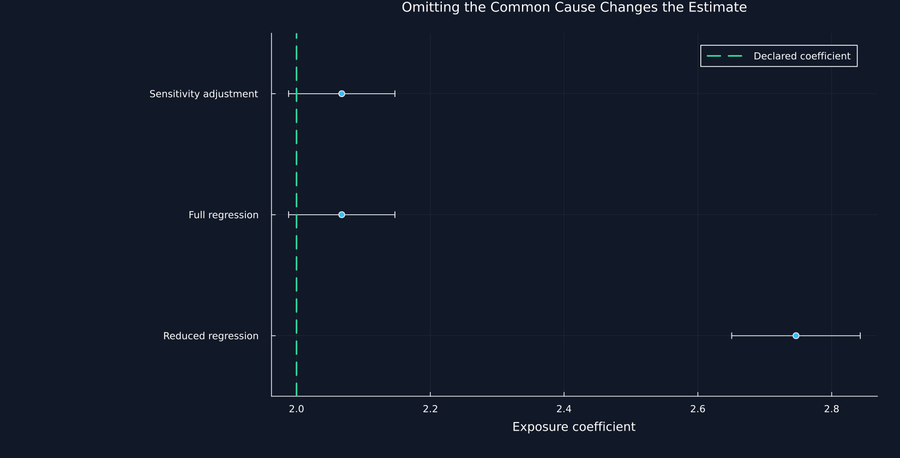

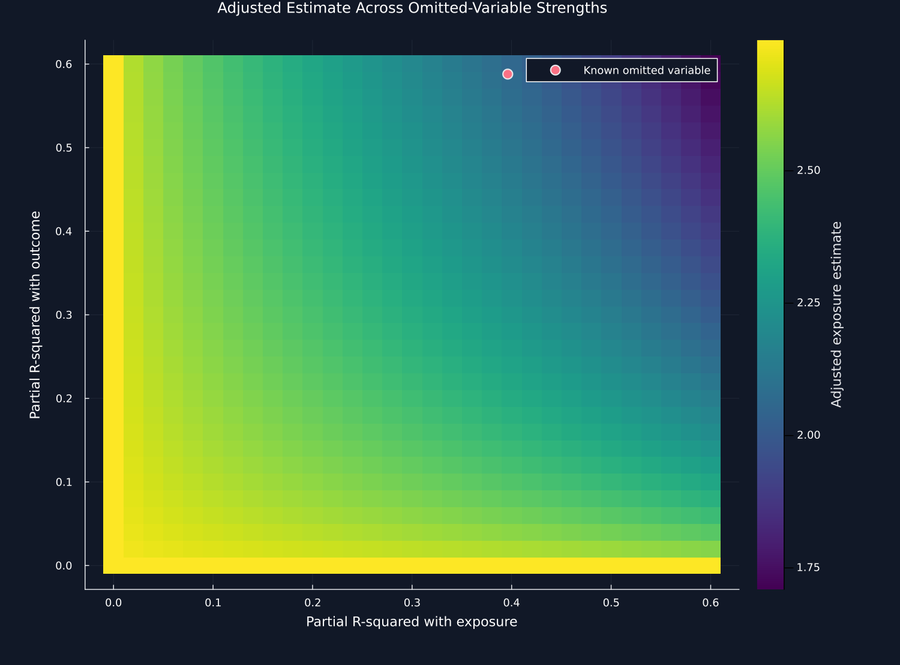

In [1]:
function generated_sensitivity()
    values=normal_block(store,"generated")
    x,z,noise_d,noise_y=eachcol(values)
    d=.8 .*z+.3 .*x+noise_d
    y=2 .*d+1.4 .*z+x+noise_y
    reduced=sensitivity_ols(y,d,x)
    full=sensitivity_ols(y,d,x,z)
    d_reduced=sensitivity_ols(d,x)
    d_full=sensitivity_ols(d,x,z)
    return (;x,z,d,y,reduced,full,r2d=sensitivity_partial_r2(d_reduced,d_full),r2y=sensitivity_partial_r2(reduced,full))
end
notation = frame(["Symbol","Description"],[["Y","Outcome"],["D","Treatment or exposure of interest"],["X","Included control variables"],["Z","Candidate omitted variable"],["tau","Exposure coefficient in the reduced regression"],["tau_Z","Exposure coefficient after adding Z"],["R2 D with Z given X","Partial R-squared of Z with the exposure"],["R2 Y with Z given D and X","Partial R-squared of Z with the outcome"]])
table(notation,"sensitivity_notation")
design = frame(["Quantity","Value"],[["Observations",500],["Random state",65],["Coefficient from Z to D",0.8],["Coefficient from X to D",0.3],["Coefficient from D to Y",2],["Coefficient from Z to Y",1.4],["Coefficient from X to Y",1]])
table(design,"sensitivity_generated_design")
generated=generated_sensitivity()
reduced,full,r2d,r2y=generated.reduced,generated.full,generated.r2d,generated.r2y
adjusted=sensitivity_estimate(r2d,r2y,reduced.coefficients[2],reduced.errors[2],reduced.degrees)
adjusted_se=sensitivity_error(r2d,r2y,reduced.errors[2],reduced.degrees)
rv_generated=zero_robustness(reduced.statistics[2],reduced.degrees)
model_comparison=frame(["Model","Exposure estimate","Standard error","Residual degrees of freedom","Explained share"],[("Reduced regression",reduced.coefficients[2],reduced.errors[2],reduced.degrees,reduced.r2),("Full regression",full.coefficients[2],full.errors[2],full.degrees,full.r2),("Sensitivity adjustment",adjusted,adjusted_se,full.degrees,NaN)])
table(model_comparison,"sensitivity_generated_models")
strengths=frame(["Strength measure","Value"],[("Partial R-squared with exposure",r2d),("Partial R-squared with outcome",r2y),("Robustness value for a zero estimate",rv_generated)])
table(strengths,"sensitivity_generated_strengths")
zero_adjustment=sensitivity_estimate(0,0,2,.1,30)
recovery=frame(["Quantity","Residual","Pass"],[("Adjusted estimate minus full estimate",adjusted-full.coefficients[2],isapprox(adjusted,full.coefficients[2])),("Adjusted standard error minus full standard error",adjusted_se-full.errors[2],isapprox(adjusted_se,full.errors[2])),("Zero-strength adjusted estimate minus supplied estimate",zero_adjustment-2,zero_adjustment==2)])
@assert all(recovery.Pass)
table(recovery,"sensitivity_recovery_checks")
coefficient_data=model_comparison[:,["Model","Exposure estimate","Standard error"]]
save_data(coefficient_data,paths,"sensitivity_generated_coefficients")
figure=scatter(coefficient_data[:,2],1:3;xerror=1.96 .*coefficient_data[:,3],yticks=(1:3,coefficient_data[:,1]),color=palette.cyan,label="",xlabel="Exposure coefficient",title="Omitting the Common Cause Changes the Estimate",ylims=(.5,3.5),size=(1100,560),left_margin=45Plots.mm)
vline!(figure,[2.];color=palette.green,linestyle=:dash,label="Declared coefficient")
save_figure(figure,paths,"sensitivity_generated_coefficients")
grid_values=collect(range(0,.6;length=31))
grid_frame=frame(["Partial R-squared with exposure","Partial R-squared with outcome","Adjusted estimate"],[(exposure,outcome,sensitivity_estimate(exposure,outcome,reduced.coefficients[2],reduced.errors[2],reduced.degrees)) for exposure in grid_values for outcome in grid_values])
save_data(grid_frame,paths,"sensitivity_generated_surface")
surface=reshape(grid_frame[:,3],length(grid_values),length(grid_values))
figure=heatmap(grid_values,grid_values,surface;color=:viridis,xlabel="Partial R-squared with exposure",ylabel="Partial R-squared with outcome",title="Adjusted Estimate Across Omitted-Variable Strengths",colorbar_title="Adjusted exposure estimate",size=(1000,740),right_margin=14Plots.mm,legend=:topright)
scatter!(figure,[r2d],[r2y];color=palette.rose,markerstrokecolor=palette.text,markersize=6,label="Known omitted variable")
save_figure(figure,paths,"sensitivity_generated_surface")


## Calibrating sensitivity to observed adjustment

The sensitivity calculation combines the two partial R-squared values with the reduced estimate and its standard error. A robustness value asks how strong an omitted variable would have to be, in both conditional relations, to move the estimate to a stated target. If the target is zero, the value summarizes the strength needed to remove the estimated sign under the sensitivity model. It is a compact description, not evidence that such a variable is absent.

Row,Case,Adjusted estimate,Adjusted standard error
,String,Float64,Float64
1,No exposure relation and no outcome relation,2.0,0.10171
2,Moderate equal strengths,1.94226,0.10171
3,Stronger exposure relation,1.88661,0.115328


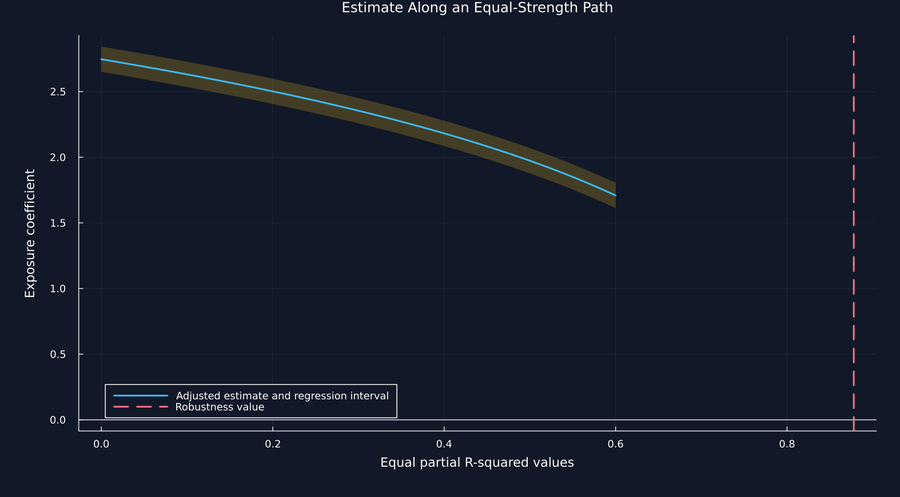

In [2]:
identity_cases=[("No exposure relation and no outcome relation",0.,0.),("Moderate equal strengths",.1,.1),("Stronger exposure relation",.3,.1)]
identity_checks=frame(["Case","Adjusted estimate","Adjusted standard error"],[(name,sensitivity_estimate(exposure,outcome,2,.1,30),sensitivity_error(exposure,outcome,.1,30)) for (name,exposure,outcome) in identity_cases])
table(identity_checks,"sensitivity_identity_cases")
diagonal=frame(["Equal partial R-squared","Adjusted estimate","Lower 95 percent limit","Upper 95 percent limit"],[(strength,estimate,estimate-1.96standard_error,estimate+1.96standard_error) for strength in range(0,.6;length=31) for estimate in (sensitivity_estimate(strength,strength,reduced.coefficients[2],reduced.errors[2],reduced.degrees),) for standard_error in (sensitivity_error(strength,strength,reduced.errors[2],reduced.degrees),)])
save_data(diagonal,paths,"sensitivity_equal_strength_path")
figure=plot(diagonal[:,1],diagonal[:,2];ribbon=(diagonal[:,2]-diagonal[:,3],diagonal[:,4]-diagonal[:,2]),color=palette.cyan,fillcolor=palette.amber,fillalpha=.22,label="Adjusted estimate and regression interval",xlabel="Equal partial R-squared values",ylabel="Exposure coefficient",title="Estimate Along an Equal-Strength Path",size=(1050,580),legend=:bottomleft)
hline!(figure,[0.];color=palette.text,linewidth=1,label="")
vline!(figure,[rv_generated];color=palette.rose,linestyle=:dash,label="Robustness value")
save_figure(figure,paths,"sensitivity_equal_strength_path")


## Public County Regressions

The public calculation uses the 2003 to 2007 change in log employment as $Y$. The fixed treated-cohort indicator is $D$. Baseline log population and baseline log employment are observed controls. These regressions describe how the exposure coefficient changes when the two baseline variables are included. For each observed-variable benchmark, the adjustment direction follows the signs of the fitted relations: it can move the exposure estimate toward zero or away from zero. The calculation does not establish that either model identifies a causal effect.

### Y public

In [3]:
raw,counties=sensitivity_counties()
y_public,d_public,population_public,employment_public=counties[:,7],counties[:,2],counties[:,6],counties[:,3]
public_models=[("Treatment indicator only",sensitivity_ols(y_public,d_public)),("Add baseline population",sensitivity_ols(y_public,d_public,population_public)),("Add baseline employment",sensitivity_ols(y_public,d_public,employment_public)),("Add both baseline variables",sensitivity_ols(y_public,d_public,population_public,employment_public))]
public_comparison=frame(["Model","Exposure estimate","Standard error","Test quantity","Explained share","Residual degrees of freedom"],[(name,model.coefficients[2],model.errors[2],model.statistics[2],model.r2,model.degrees) for (name,model) in public_models])
table(public_comparison,"mpdta_regression_models")
public_summary=frame(["Quantity","Value"],[("County count",nrow(counties)),("Treatment fraction",mean(d_public)),("Mean employment change",mean(y_public)),("Employment-change standard deviation",std(y_public))])
table(public_summary,"mpdta_regression_summary")
full_public=last(public_models)[2]
benchmark_records=[]
for (name,omitted,retained) in [("Baseline population",population_public,employment_public),("Baseline employment",employment_public,population_public)]
    outcome_restricted=sensitivity_ols(y_public,d_public,retained)
    exposure_restricted=sensitivity_ols(d_public,retained)
    exposure_expanded=sensitivity_ols(d_public,retained,omitted)
    exposure_strength=sensitivity_partial_r2(exposure_restricted,exposure_expanded)
    outcome_strength=sensitivity_partial_r2(outcome_restricted,full_public)
    reduce_direction=abs(full_public.coefficients[2])<=abs(outcome_restricted.coefficients[2])
    adjusted_public=sensitivity_estimate(exposure_strength,outcome_strength,outcome_restricted.coefficients[2],outcome_restricted.errors[2],outcome_restricted.degrees;reduce=reduce_direction)
    adjusted_public_se=sensitivity_error(exposure_strength,outcome_strength,outcome_restricted.errors[2],outcome_restricted.degrees)
    push!(benchmark_records,(name,reduce_direction ? "Toward zero" : "Away from zero",exposure_strength,outcome_strength,outcome_restricted.coefficients[2],adjusted_public,full_public.coefficients[2],adjusted_public_se,full_public.errors[2]))
end
benchmarks=frame(["Omitted observed variable","Adjustment direction","Partial R-squared with exposure","Partial R-squared with outcome","Reduced estimate","Adjusted estimate","Full estimate","Adjusted standard error","Full standard error"],benchmark_records);


Row,Model,Exposure estimate,Standard error,Test quantity,Explained share,Residual degrees of freedom
,String,Float64,Float64,Float64,Float64,Int64
1,Treatment indicator only,-0.0385377,0.0229846,-1.67668,0.00561338,498
2,Add baseline population,-0.0448117,0.0230966,-1.94019,0.0144683,497
3,Add baseline employment,-0.0407668,0.0231698,-1.75948,0.00683379,497
4,Add both baseline variables,-0.0441629,0.0228647,-1.93149,0.0361737,496


Row,Quantity,Value
,String,Real
1,County count,500
2,Treatment fraction,0.382
3,Mean employment change,-0.00821887
4,Employment-change standard deviation,0.250169


### Public Coefficient Across Declared Control Sets

Row,Omitted observed variable,Adjustment direction,Partial R-squared with exposure,Partial R-squared with outcome,Reduced estimate,Adjusted estimate,Full estimate,Adjusted standard error,Full standard error
,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Baseline population,Away from zero,0.00146109,0.0295418,-0.0407668,-0.0441629,-0.0441629,0.0228647,0.0228647
2,Baseline employment,Toward zero,7.20973e-5,0.022024,-0.0448117,-0.0441629,-0.0441629,0.0228647,0.0228647


Row,Omitted observed variable,Adjustment direction,Partial R-squared with exposure,Partial R-squared with outcome
,String,String,Float64,Float64
1,Baseline population,Away from zero,0.00146109,0.0295418
2,Baseline employment,Toward zero,7.20973e-5,0.022024


Row,Calculation,Robustness value,Exposure estimate,Standard error
,String,Float64,Float64,Float64
1,Controlled generated regression,0.877875,2.7467,0.0490459
2,Public regression with both baseline variables,0.0830471,-0.0441629,0.0228647


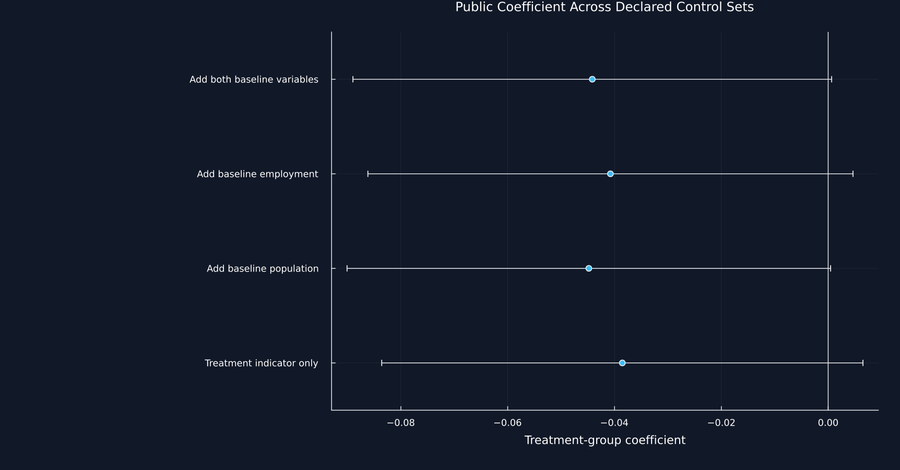

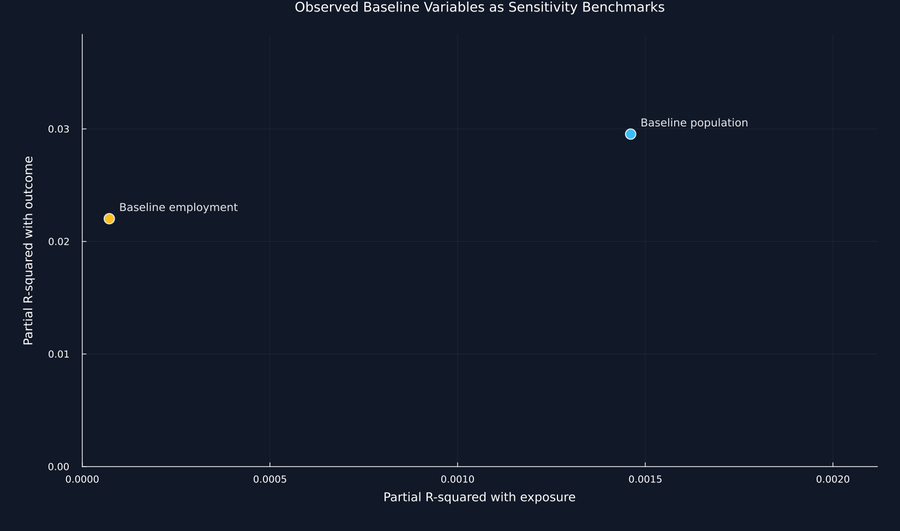

In [3]:
@assert all(isapprox.(benchmarks[:,6],benchmarks[:,7]))
@assert all(isapprox.(benchmarks[:,8],benchmarks[:,9]))
table(benchmarks,"mpdta_observed_covariate_benchmarks")
benchmark_book=benchmarks[:,1:4]
table(benchmark_book,"mpdta_observed_covariate_benchmarks_book")
public_rv=zero_robustness(full_public.statistics[2],full_public.degrees)
robustness=frame(["Calculation","Robustness value","Exposure estimate","Standard error"],[("Controlled generated regression",rv_generated,reduced.coefficients[2],reduced.errors[2]),("Public regression with both baseline variables",public_rv,full_public.coefficients[2],full_public.errors[2])])
table(robustness,"sensitivity_robustness_values")
public_plot=public_comparison[:,["Model","Exposure estimate","Standard error"]]
save_data(public_plot,paths,"mpdta_regression_coefficients")
figure=scatter(public_plot[:,2],1:4;xerror=1.96 .*public_plot[:,3],yticks=(1:4,public_plot[:,1]),color=palette.cyan,label="",xlabel="Treatment-group coefficient",title="Public Coefficient Across Declared Control Sets",ylims=(.5,4.5),size=(1150,600),left_margin=60Plots.mm)
vline!(figure,[0.];color=palette.text,linewidth=1,label="")
save_figure(figure,paths,"mpdta_regression_coefficients")
benchmark_plot=benchmarks[:,["Omitted observed variable","Partial R-squared with exposure","Partial R-squared with outcome"]]
save_data(benchmark_plot,paths,"mpdta_observed_covariate_benchmarks")
figure=scatter(benchmark_plot[:,2],benchmark_plot[:,3];color=[palette.cyan,palette.amber],markersize=7,xlabel="Partial R-squared with exposure",ylabel="Partial R-squared with outcome",title="Observed Baseline Variables as Sensitivity Benchmarks",legend=false,size=(1100,650),xlims=(0,maximum(benchmark_plot[:,2])*1.45),ylims=(0,maximum(benchmark_plot[:,3])*1.3))
for row in eachrow(benchmark_plot)
    annotate!(figure,row[2]+.02maximum(benchmark_plot[:,2]),row[3]+.035maximum(benchmark_plot[:,3]),text(row[1],9,palette.text,:left))
end
save_figure(figure,paths,"mpdta_observed_covariate_benchmarks")
